In [41]:
#invite people for the Kaggle party
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [42]:
df=pd.read_csv("Housing.csv")

In [43]:
df.shape

(545, 13)

In [44]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [46]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [47]:
df['price'].describe()

count    5.450000e+02
mean     4.766729e+06
std      1.870440e+06
min      1.750000e+06
25%      3.430000e+06
50%      4.340000e+06
75%      5.740000e+06
max      1.330000e+07
Name: price, dtype: float64

In [48]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [49]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='price', ylabel='Count'>

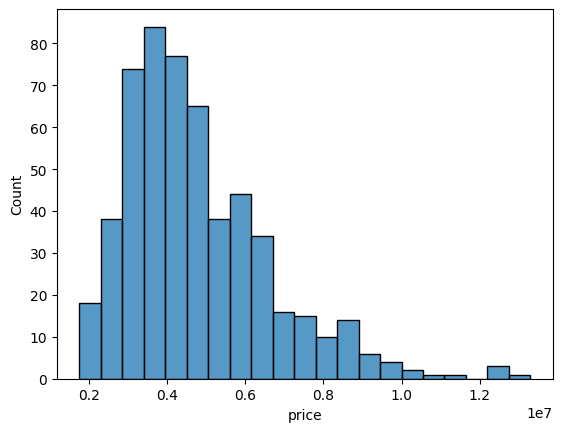

In [50]:
sns.histplot(df['price'])


In [51]:
df['price'].skew()

np.float64(1.2122388370279802)

<Axes: xlabel='price'>

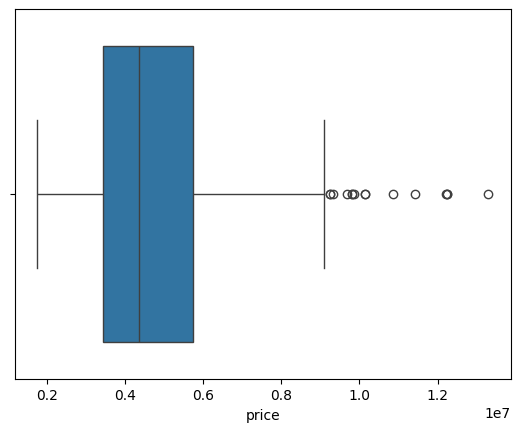

In [52]:
sns.boxplot(x=df['price'])


<Axes: xlabel='area', ylabel='Count'>

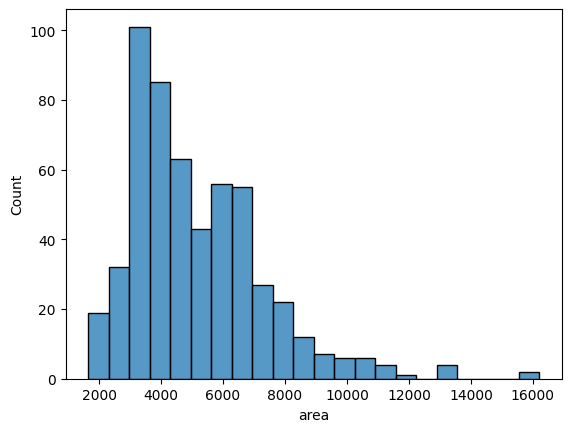

In [53]:
sns.histplot(df['area'])

<Axes: xlabel='area'>

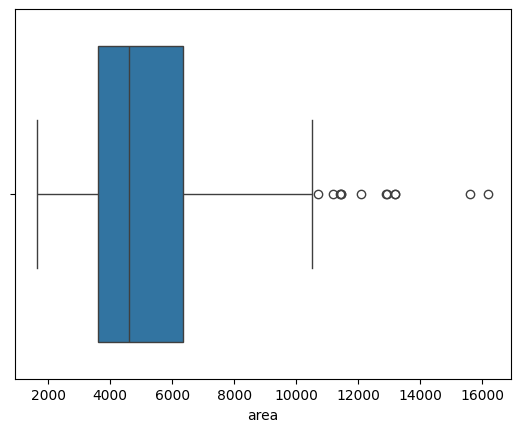

In [54]:
sns.boxplot(x=df['area'])

<Axes: xlabel='bedrooms', ylabel='Count'>

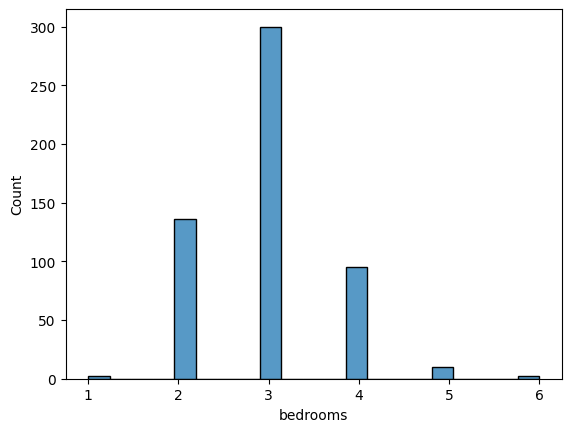

In [55]:
sns.histplot(df['bedrooms'])

<Axes: xlabel='bedrooms'>

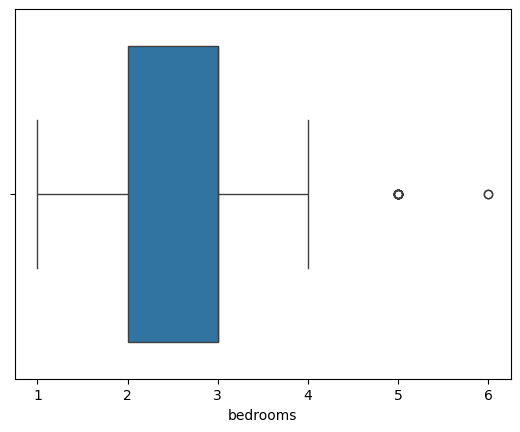

In [56]:
sns.boxplot(x=df['bedrooms'])

<Axes: xlabel='bathrooms', ylabel='Count'>

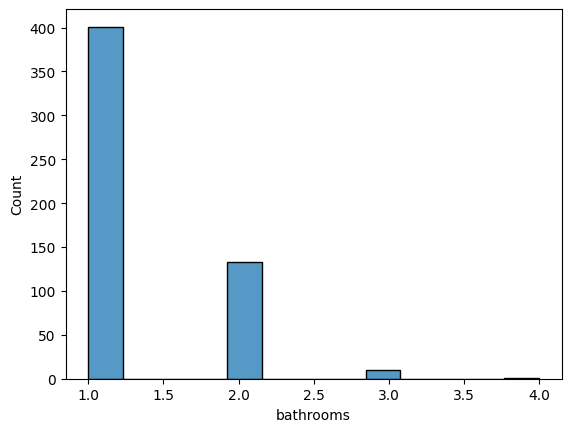

In [57]:
sns.histplot(df['bathrooms'])

<Axes: xlabel='bathrooms'>

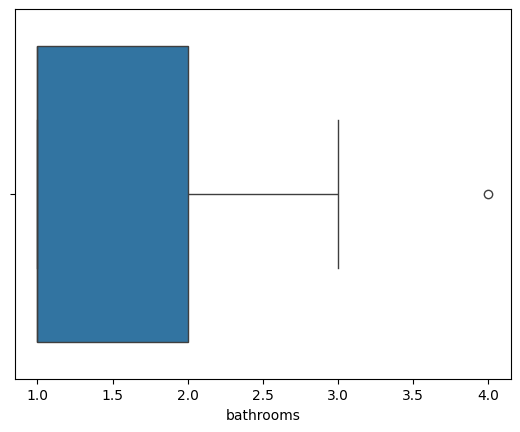

In [58]:
sns.boxplot(x=df['bathrooms'])

<Axes: xlabel='stories', ylabel='Count'>

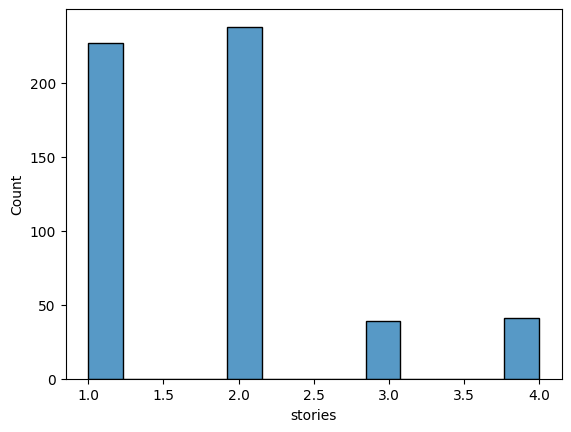

In [59]:
sns.histplot(df['stories'])

<Axes: xlabel='stories'>

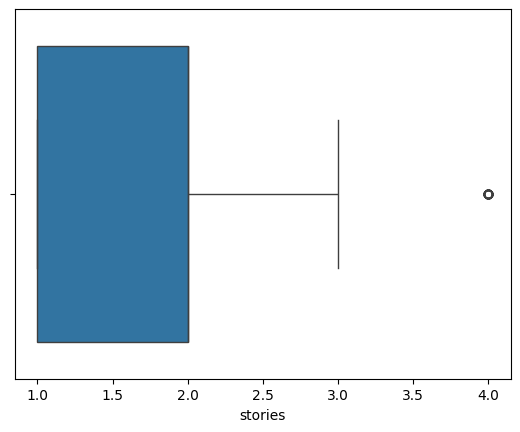

In [60]:
sns.boxplot(x=df['stories'])

<Axes: xlabel='parking', ylabel='Count'>

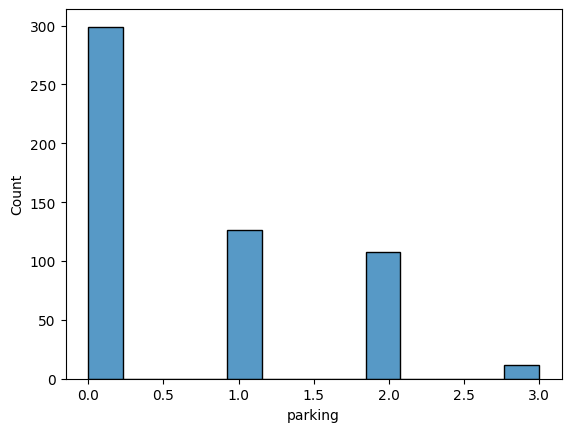

In [61]:
sns.histplot(df['parking'])

<Axes: xlabel='parking'>

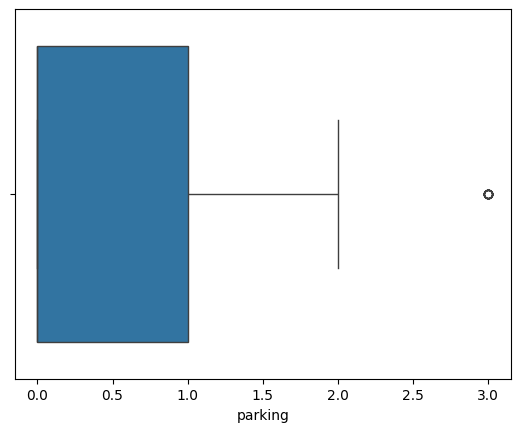

In [62]:
sns.boxplot(x=df['parking'])

Analysis of Categorical dataset

<Axes: xlabel='furnishingstatus', ylabel='count'>

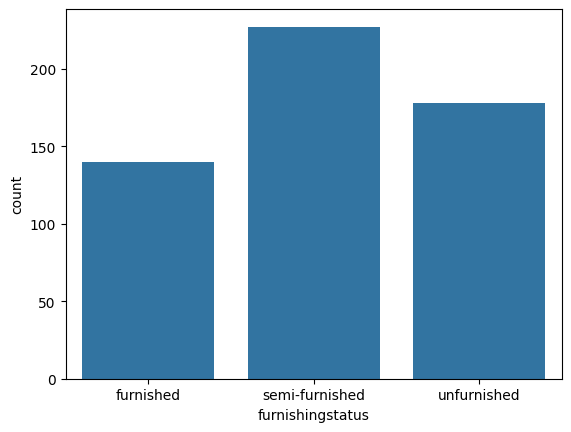

In [63]:
sns.countplot(x='furnishingstatus',data=df)

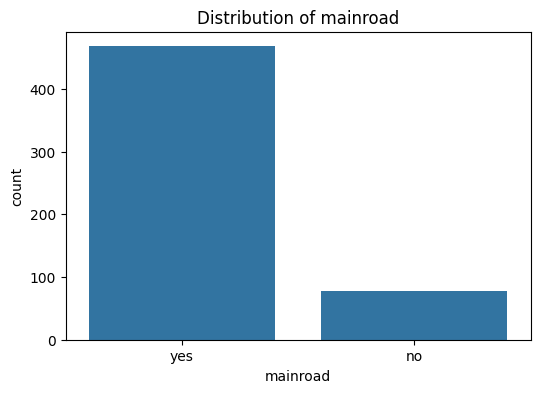

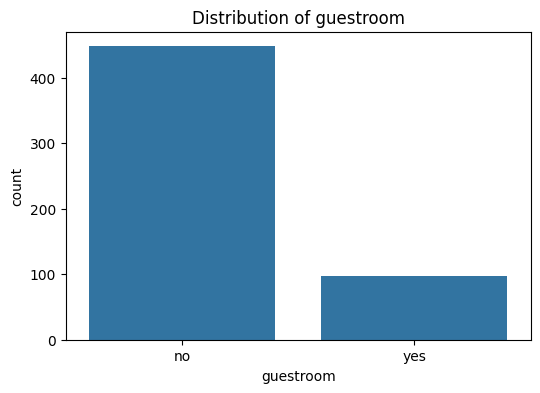

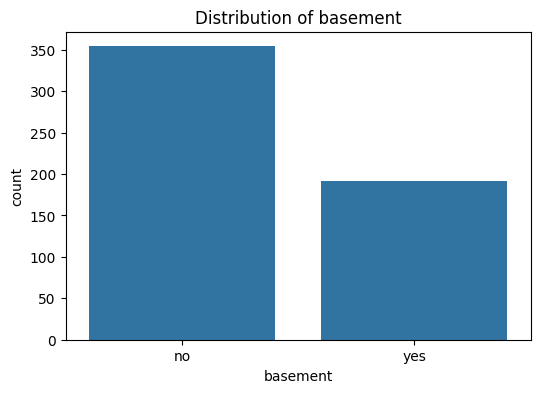

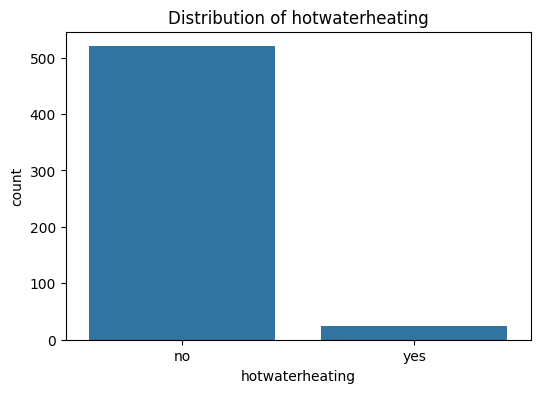

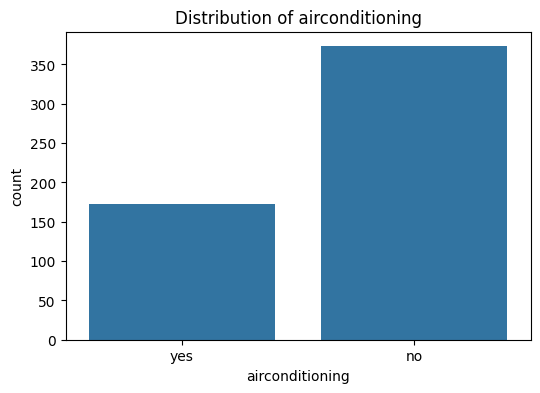

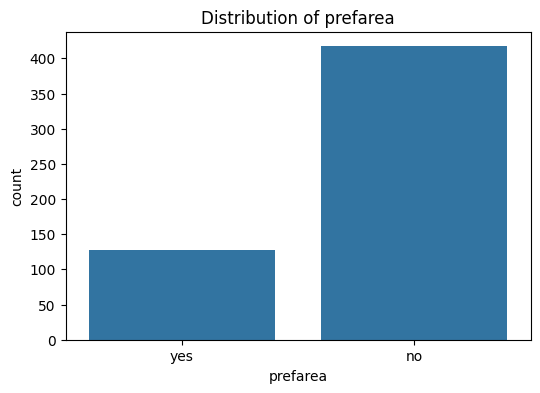

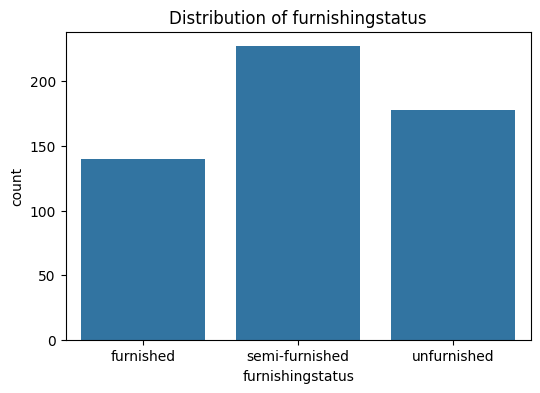

In [64]:
cat_cols = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea',
    'furnishingstatus'
]

for col in cat_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.show()

<Axes: xlabel='area', ylabel='price'>

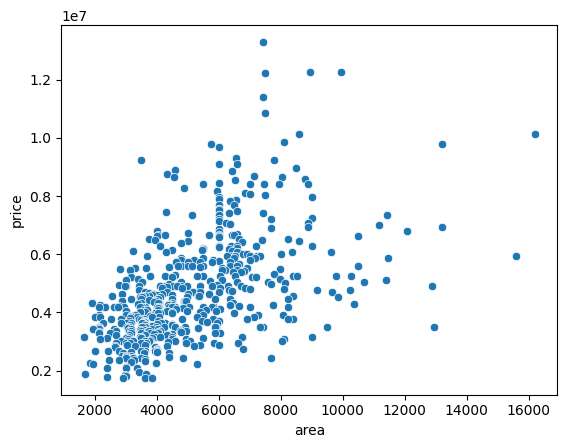

In [65]:
sns.scatterplot(x='area',y='price',data=df)

<Axes: xlabel='bedrooms', ylabel='price'>

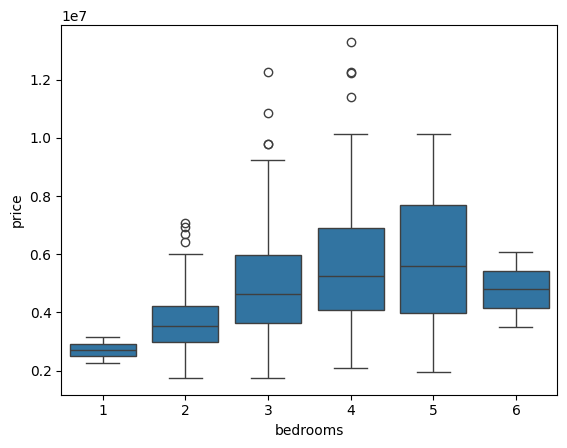

In [66]:
sns.boxplot(x='bedrooms',y='price',data=df)

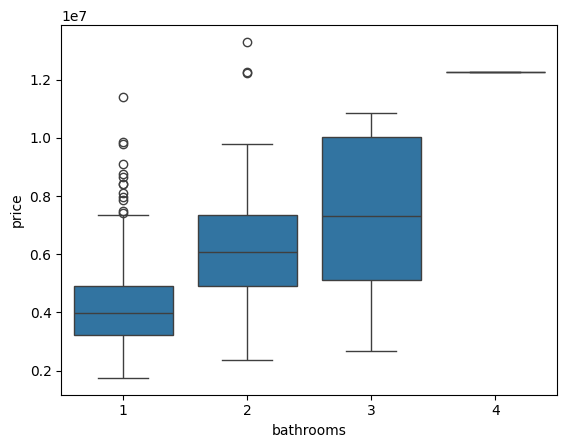

In [67]:
sns.boxplot(x='bathrooms', y='price', data=df)
plt.show()


step 1: importing modules

In [69]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

step 2: identify or choose on which want to apply k means clustering

In [70]:
x=df[['area','price']]

In [71]:
x

,area,price
0,7420,13300000
1,8960,12250000
2,9960,12250000
3,7500,12215000
4,7420,11410000
...,...,...
540,3000,1820000
541,2400,1767150
542,3620,1750000
543,2910,1750000


In [72]:
scaler=StandardScaler()
x_scales=scaler.fit_transform(x)

In [74]:
x_scaled[1]

array([1.75700953, 4.00448405])

In [77]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

C:\Users\anjal\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\anjal\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\anjal\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\anjal\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

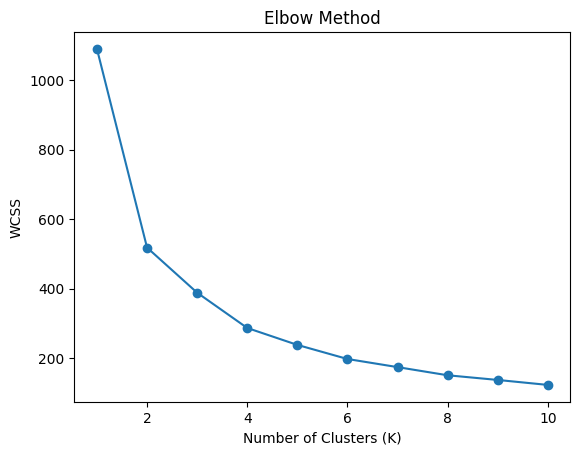

In [78]:
plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.show()

In [80]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(x_scaled)

C:\Users\anjal\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


,n_clusters,4
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [82]:
df['cluster'] = kmeans.labels_

In [83]:
df[['area', 'price', 'cluster']].head(10)

,area,price,cluster
0,7420,13300000,0
1,8960,12250000,0
2,9960,12250000,0
3,7500,12215000,0
4,7420,11410000,0
5,7500,10850000,0
6,8580,10150000,0
7,16200,10150000,3
8,8100,9870000,0
9,5750,9800000,0


In [84]:
df['cluster'].value_counts().sort_index()

cluster
0     60
1    276
2    175
3     34
Name: count, dtype: int64

In [86]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

kmeans.fit(x_scaled)

df['cluster'] = kmeans.labels_

C:\Users\anjal\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


In [87]:
df[['area', 'price', 'cluster']].head(10)

,area,price,cluster
0,7420,13300000,0
1,8960,12250000,0
2,9960,12250000,0
3,7500,12215000,0
4,7420,11410000,0
5,7500,10850000,0
6,8580,10150000,0
7,16200,10150000,3
8,8100,9870000,0
9,5750,9800000,0


In [88]:
df['cluster'].value_counts().sort_index()

cluster
0     60
1    276
2    175
3     34
Name: count, dtype: int64

In [90]:
from sklearn.metrics import silhouette_score

score = silhouette_score(x_scaled, df['cluster'])

print("Silhouette Score:", score)

Silhouette Score: 0.4369954919147402


In [92]:
from sklearn.metrics import silhouette_score

score = silhouette_score(x_scaled, df['cluster'])

print("Silhouette Score:", score)
print("Clustering Score:", score * 100, "%")

Silhouette Score: 0.4369954919147402
Clustering Score: 43.69954919147402 %
